# Glint360k dataset extraction script

### Dataset Structure Transformation

The data in this dataset is currently structured as follows:

```text
glint360/
  ├── 0/
  │    ├── 1.jpg
  │    ├── 2.jpg
  │    ├── 3.jpg
  │    └── ...
  ├── 1/
  │    ├── 111.jpg
  │    ├── 112.jpg
  │    └── ...

we will turn it into:
Images/
  |--1.jpg
  |--2.jpg
  |--3.jpg
  |--...

and a labels.csv file that holds the labels



Data Source: https://academictorrents.com/details/e5f46ee502b9e76da8cc3a0e4f7c17e4000c7b1e

Notes:
*  The dataset needs to be unzipped to extract the train.rec and train.idx files which are then processed by this notebook to extract the images and standardize them.
*  Change the paths below so that they point to the train.rec and train.idx files. Also, specify the output directory for the data.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import mxnet as mx
import os
import cv2
import pandas as pd, shutil

In [2]:
rec_path = os.path.join('..', 'data', 'datasets', 'face recognition', 'glint360k', 'glint360k_unzipped', 'train.rec')
idx_path = os.path.join('..', 'data', 'datasets', 'face recognition', 'glint360k', 'glint360k_unzipped', 'train.idx')
output_dir = os.path.join('..', 'data', 'datasets', 'face recognition', 'glint360k')

In [ ]:
record = mx.recordio.MXIndexedRecordIO(idx_path, rec_path, 'r')

In [3]:


for i, key in enumerate(record.keys):
    try:
        header, img = mx.recordio.unpack(record.read_idx(key))
        if isinstance(header.label, list) or isinstance(header.label, np.ndarray):
            label = int(header.label[0])
        else:
            label = int(header.label)
            
        img_arr = cv2.cvtColor(mx.image.imdecode(img).asnumpy(), cv2.COLOR_BGR2RGB)  # Decode to ndarray
        save_dir = os.path.join(output_dir, str(label))
        os.makedirs(save_dir, exist_ok=True)
        
        
        cv2.imwrite(os.path.join(save_dir, f"{i}.jpg"), img_arr)

        if i % 10000 == 0:
            print(f"Processed {i}/{len(record.keys)}")
    except:
        print(i, label)
        continue

Processed 0/17451890
Processed 10000/17451890
Processed 20000/17451890
Processed 30000/17451890
Processed 40000/17451890
Processed 50000/17451890
Processed 60000/17451890
Processed 70000/17451890
Processed 80000/17451890
Processed 90000/17451890
Processed 100000/17451890
Processed 110000/17451890
Processed 120000/17451890
Processed 130000/17451890
Processed 140000/17451890
Processed 150000/17451890
Processed 160000/17451890
Processed 170000/17451890
Processed 180000/17451890
Processed 190000/17451890
Processed 200000/17451890
Processed 210000/17451890
Processed 220000/17451890
Processed 230000/17451890
Processed 240000/17451890
Processed 250000/17451890
Processed 260000/17451890
Processed 270000/17451890
Processed 280000/17451890
Processed 290000/17451890
Processed 300000/17451890
Processed 310000/17451890
Processed 320000/17451890
Processed 330000/17451890
Processed 340000/17451890
Processed 350000/17451890
Processed 360000/17451890
Processed 370000/17451890
Processed 380000/17451890


### Standardizing the data directory

In [ ]:
output_dir_listed = os.listdir(output_dir)
output_dir_listed.remove('Images')
length = len(output_dir_listed)

images = []
labels = []

for dir in range(length): # directories are numbered 0 to length-1, so iterate over them using the range function to make sure they are sorted
    for file in os.listdir(os.path.join(output_dir, str(dir))):
        if file.endswith('.jpg'):
            images.append(file)
            labels.append(dir)
            shutil.move(os.path.join(output_dir, str(dir), file), os.path.join(output_dir, 'Images', file))

    os.rmdir(os.path.join(output_dir, str(dir)))

labels = pd.DataFrame(data = {'filename' : images, 'label' : labels})
labels.to_csv(os.path.join(output_dir, 'labels.csv'), index = False)
            

In [21]:
labels = pd.DataFrame(data = {'filename' : images, 'label' : labels})
labels.to_csv(os.path.join(output_dir, 'labels.csv'), index = False)

Note: This dataset is used for face recognition during the pretraining phase. Therefore, it will not be split into training, testing and validation splits.

## EDA

In [3]:
labels = pd.read_csv(os.path.join(output_dir, 'labels.csv'))

In [4]:
print(f"Total dataset length: {len(labels)}")

Total dataset length: 17091657


In [5]:
print(f'Total number of classes: {len(labels.label.unique())}')

Total number of classes: 360232


In [6]:
from matplotlib import pyplot as plt

In [7]:
classes, counts = np.unique(labels.label, return_counts = True)
sorted = np.argsort(counts)
counts = counts[sorted]

In [8]:
print(f'Min class Images: {np.min(counts)}')
print(f'Max class Images: {np.max(counts)}')

Min class Images: 3
Max class Images: 1868


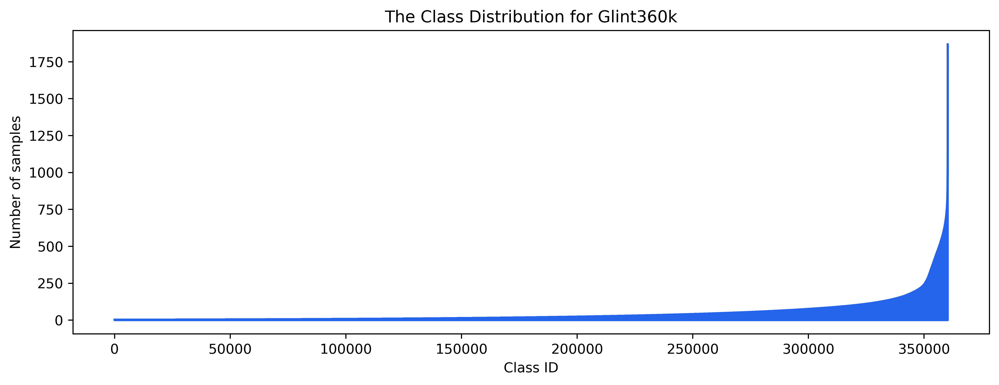

In [9]:
plt.figure(figsize = (12, 4), dpi = 450)
plt.plot(classes, counts, color = "#2563eb")
plt.fill_between(classes, counts, color = '#2563eb', linewidth = 1.5)
plt.title('The Class Distribution for Glint360k')
plt.xlabel('Class ID')
plt.ylabel('Number of samples')
plt.savefig(
    os.path.join('..', 'data', 'figures', 'Face Recognition', 'Glint360k', 'The Class Distribution for Glint360k')
)
plt.show()

In [10]:
sample_images = []
sample_labels = []
for i in range(4): # choose 4 random classes
    class_idx = np.random.randint(low = 0, high = len(labels.label.unique()))
    class_labels = labels[labels['label'] == class_idx]

    while len(class_labels) < 4: # Make sure the chosen class has at least 4 images
            class_idx = np.random.randint(low = 0, high = len(labels.label.unique()))
            class_labels = labels[labels['label'] == class_idx]
            
    indices = []
    for j in range(4): # choose 4 random images within the class
        idx = np.random.randint(low = 0, high = len(class_labels))
        
        while idx in indices: # Make sure the chosen image hasn't been chosen before
            idx = np.random.randint(low = 0, high = len(class_labels))

        filename = class_labels.iloc[idx]['filename']
        label = class_labels.iloc[idx]['label']
        indices.append(idx)
        sample_images.append(filename)
        sample_labels.append(label)

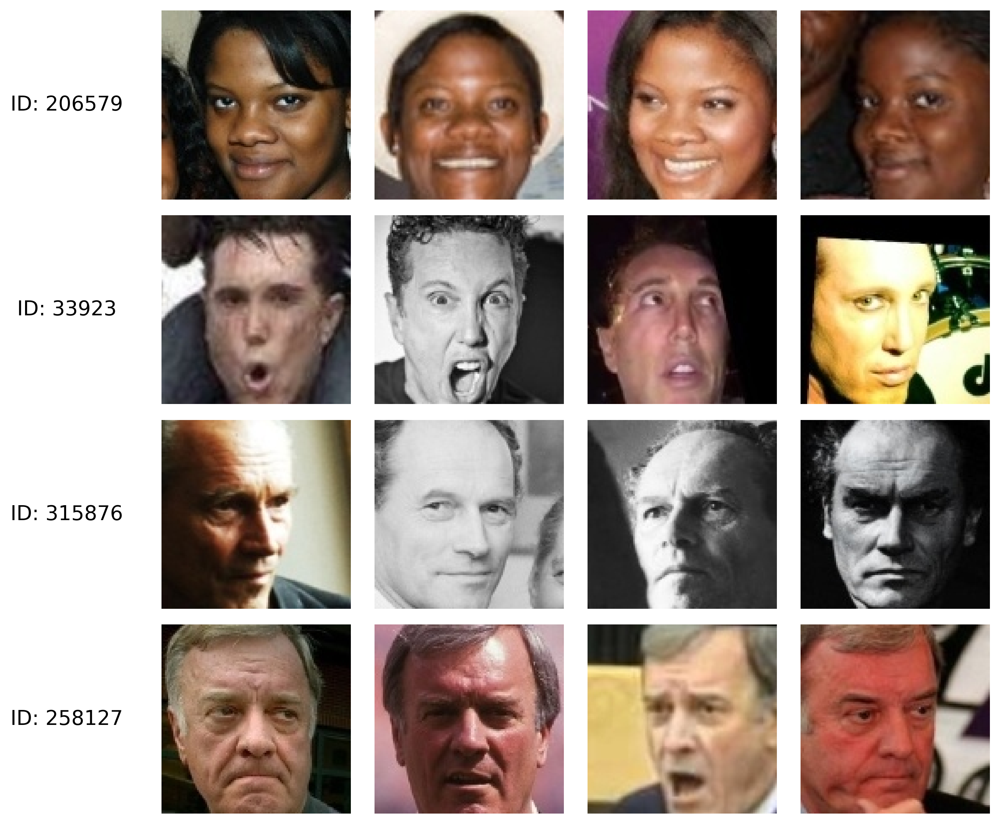

In [11]:
fig, axes = plt.subplots(4, 4, figsize = (10, 8), dpi = 300)
fig.set_dpi(300)
for i in range(4):
    first_ax = axes[i, 0]

    first_ax.text(
    -0.5, 0.5, f'ID: {sample_labels[i * 4]}',
    transform = first_ax.transAxes,
    va = 'center',
    ha = 'center',
    rotation = 'horizontal',
    fontsize = 14,
    )

    for j in range(4):
        ax = axes[i, j]
        image = plt.imread(os.path.join(output_dir, 'Images', sample_images[i * 4 + j]))
        ax.imshow(image)
        ax.axis('off')
plt.tight_layout()
plt.subplots_adjust(left = 0.15)
plt.savefig(
    os.path.join('..', 'data', 'figures', 'Face Recognition', 'Glint360k', 'Sample Images from Glint360k')
)
plt.show()